# Detecção de exoplanetas com dados do Kepler e do TESS

Classificador de candidatos a planeta (**planeta confirmado × falso positivo**) usando catálogos do NASA Exoplanet Archive e, numa segunda fase, features extraídas das **curvas de luz** do Kepler.

**Perguntas do projeto**
1. Dá para separar planetas de falsos positivos só com as medidas dos catálogos (período, profundidade, duração, parâmetros da estrela)?
2. O que acontece no TESS, e o que o modelo aprende transfere de uma missão para a outra?
3. Features extraídas das curvas de luz (forma do trânsito, eclipse secundário) acrescentam informação ao que o catálogo já tem?

**Como rodar:** adicione o dataset *Kepler & TESS Exoplanet Data* (autor `vijayveersingh`) como entrada e use *Run All*. A seção 4 usa curvas de luz baixadas do MAST: ela vem desligada (`RUN_EXTRACTION = False`) e usa um CSV de features já calculado, se existir. Com `RUN_EXTRACTION = True` o notebook baixa as curvas e calcula as features (cerca de 1h20 para 1.000 KOIs).

**Convenções:** toda validação separa os dados **por estrela** (uma estrela nunca aparece no treino e no teste ao mesmo tempo), e a métrica principal é o ROC-AUC, porque as classes são desbalanceadas.

## 0. Configuração

In [4]:
import os, glob, time, shutil, warnings, textwrap
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             classification_report, precision_score, recall_score)
warnings.filterwarnings("ignore")

SEED = 42
RUN_EXTRACTION = False   # True: baixa curvas do MAST e extrai features (~1h20 para 1.000 KOIs)
LIMITE_MIN     = 600     # tempo máximo da extração, em minutos
N_POR_CLASSE   = 500     # KOIs por classe na extração
N_THREADS      = 3       # downloads em paralelo

OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)

def find(padrao):
    """Procura um arquivo em /kaggle/input, em $DATA_DIR e na pasta de saída."""
    for raiz in ["/kaggle/input", os.environ.get("DATA_DIR", "."), OUT]:
        achados = sorted(glob.glob(os.path.join(raiz, "**", padrao), recursive=True))
        if achados:
            return achados[0]
    raise FileNotFoundError(padrao)

def auc_fp(y, p):
    """PR-AUC da classe 'falso positivo' (piso = fração de falsos positivos)."""
    return average_precision_score(1 - np.asarray(y), 1 - np.asarray(p))

## 1. Os dados

In [5]:
koi = pd.read_csv(find("q1_q8_koi*.csv"), comment="#")
toi = pd.read_csv(find("TOI_*.csv"), comment="#")
print("KOI (Kepler):", koi.shape, "| TOI (TESS):", toi.shape)
print("Disposições KOI:", koi.koi_disposition.value_counts().to_dict())
print("Disposições TOI:", toi.tfopwg_disp.value_counts(dropna=False).to_dict())
print()
for padrao in ["q1_q17_dr25_tce*.csv", "q1_q17_dr25_koifpp*.csv", "keplerstellar*.csv",
               "STELLARHOSTS*.csv", "PS_*.csv"]:
    f = find(padrao)
    print(f"{os.path.basename(f):55s} {os.path.getsize(f)/1e6:8.1f} MB")

KOI (Kepler): (3865, 49) | TOI (TESS): (7372, 65)
Disposições KOI: {'CONFIRMED': 2317, 'FALSE POSITIVE': 701, 'NOT DISPOSITIONED': 579, 'CANDIDATE': 268}
Disposições TOI: {'PC': 4690, 'FP': 1113, 'KP': 548, 'CP': 485, 'APC': 438, 'FA': 96, nan: 2}

q1_q17_dr25_tce_2025.02.03_04.32.18.csv                      8.5 MB
q1_q17_dr25_koifpp_2025.02.03_06.14.34.csv                   2.5 MB
keplerstellar_2025.02.03_04.41.47.csv                      252.5 MB
STELLARHOSTS_2025.02.03_06.11.17.csv                        24.9 MB
PS_2025.02.03_05.09.36.csv                                  33.9 MB


O dataset é **todo tabular**: não há curvas de luz. As tabelas usadas no modelo são a de KOIs do Kepler (`q1_q8_koi`, com a coluna `koi_disposition`) e a de TOIs do TESS (`tfopwg_disp`). As demais (TCEs, probabilidade de falso positivo, catálogo estelar, planetas confirmados) não entram nos modelos desta versão.

## 2. Kepler: classificador com as medidas do catálogo

**Rótulos:** `CONFIRMED` = 1 e `FALSE POSITIVE` = 0. `CANDIDATE` e `NOT DISPOSITIONED` ficam fora do treino (ainda não têm resposta) e são previstos no final.

**Features:** medidas do sinal e da estrela. Ficam de fora as colunas que "entregam" a resposta (`koi_pdisposition`, flags de falso positivo, `koi_score`, `fpp_prob`) e `koi_insol`, que está 100% vazia nesta versão da tabela.

In [6]:
print("koi_insol: % de nulos =", round(koi.koi_insol.isna().mean() * 100, 1), "-> descartada")

kdf = koi[koi.koi_disposition.isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
kdf["y"] = (kdf.koi_disposition == "CONFIRMED").astype(int)

FEATS_K = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",
           "koi_prad", "koi_teq", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]

print("Linhas rotuladas:", len(kdf), "| estrelas únicas:", kdf.kepid.nunique())
print("Proporção das classes:", kdf.y.value_counts(normalize=True).round(3).to_dict())
print("Nulos (%):", (kdf[FEATS_K].isna().mean() * 100).round(1).to_dict())

koi_insol: % de nulos = 100.0 -> descartada
Linhas rotuladas: 3018 | estrelas únicas: 2350
Proporção das classes: {1: 0.768, 0: 0.232}
Nulos (%): {'koi_period': 0.0, 'koi_duration': 0.0, 'koi_depth': 0.0, 'koi_impact': 0.0, 'koi_model_snr': 0.0, 'koi_prad': 0.0, 'koi_teq': 0.0, 'koi_steff': 0.0, 'koi_slogg': 0.0, 'koi_srad': 0.0, 'koi_kepmag': 0.0}


### 2.1 Baseline: Random Forest

In [7]:
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                            random_state=SEED, n_jobs=-1)
proba0 = cross_val_predict(rf, kdf[FEATS_K], kdf.y, groups=kdf.kepid,
                           cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]

print("ROC-AUC:", round(roc_auc_score(kdf.y, proba0), 3))
print("PR-AUC (planeta): ", round(average_precision_score(kdf.y, proba0), 3),
      "  <- inflada: o piso é a fração de planetas (0,77)")
print("PR-AUC (falso positivo):", round(auc_fp(kdf.y, proba0), 3), "  <- piso 0,23")
print()
print(classification_report(kdf.y, proba0 > 0.5, target_names=["Falso positivo", "Planeta"]))

ROC-AUC: 0.915
PR-AUC (planeta):  0.967   <- inflada: o piso é a fração de planetas (0,77)
PR-AUC (falso positivo): 0.823   <- piso 0,23

                precision    recall  f1-score   support

Falso positivo       0.84      0.63      0.72       701
       Planeta       0.90      0.96      0.93      2317

      accuracy                           0.89      3018
     macro avg       0.87      0.80      0.82      3018
  weighted avg       0.88      0.89      0.88      3018



O modelo quase não perde planetas (recall alto), mas **deixa passar uma parte relevante dos falsos positivos** com o limiar de 0,5 (veja o recall da classe "Falso positivo"; esse número específico varia com a versão do scikit-learn, enquanto o ROC-AUC é estável). Como há mais planetas que falsos positivos, o modelo tende a dizer "planeta" na dúvida. A PR-AUC da classe "planeta" é inflada pelo desbalanceamento; a da classe "falso positivo" é a mais honesta.

### 2.2 Features físicas

Features que um astrônomo usaria para desconfiar de um sinal:
- `rp_rs`: raio do planeta ÷ raio da estrela (razões grandes indicam uma companheira estelar);
- `dur_ratio`: duração observada ÷ duração esperada para uma órbita circular em torno daquela estrela (calculada a partir da densidade estelar);
- logaritmos de período, profundidade e SNR (variam por ordens de grandeza).

In [8]:
def fisica_kepler(t):
    t = t.copy()
    t["log_period"] = np.log10(t["koi_period"])
    t["log_depth"]  = np.log10(t["koi_depth"].clip(lower=1))
    t["log_snr"]    = np.log10(t["koi_model_snr"].clip(lower=0.1))
    t["rp_rs"]      = t["koi_prad"] / (109.1 * t["koi_srad"])
    rho = (10 ** (t["koi_slogg"] - 4.438)) / t["koi_srad"]      # densidade relativa ao Sol
    dur_esp = 13.0 * (t["koi_period"] / 365.25) ** (1 / 3) * rho ** (-1 / 3)   # horas
    t["dur_ratio"] = t["koi_duration"] / dur_esp
    return t.replace([np.inf, -np.inf], np.nan)

kdf = fisica_kepler(kdf)
FEATS_K2 = FEATS_K + ["log_period", "log_depth", "log_snr", "rp_rs", "dur_ratio"]

rf300 = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
hgb_k = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)
configs = {"RF  originais": (rf300, FEATS_K), "RF  + novas": (rf300, FEATS_K2), "HGB + novas": (hgb_k, FEATS_K2)}

res_k = {n: [] for n in configs}
oof_hgb = None
for seed in range(5):                      # 5 divisões diferentes, sempre separadas por estrela
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for nome, (mdl, cols) in configs.items():
        p = cross_val_predict(mdl, kdf[cols], kdf.y, groups=kdf.kepid, cv=cv, method="predict_proba")[:, 1]
        res_k[nome].append(auc_fp(kdf.y, p))
        if nome == "HGB + novas" and seed == 0:
            oof_hgb = p

print("PR-AUC (falso positivo) em 5 divisões diferentes (piso = 0,23):\n")
for nome, v in res_k.items():
    print(f"{nome:14s} média={np.mean(v):.3f}  desvio={np.std(v):.3f}")

PR-AUC (falso positivo) em 5 divisões diferentes (piso = 0,23):

RF  originais  média=0.822  desvio=0.002
RF  + novas    média=0.841  desvio=0.002
HGB + novas    média=0.843  desvio=0.006


As features físicas melhoram a detecção de falsos positivos de forma **consistente** (o pior resultado do RF com features novas supera o melhor do RF original em todas as divisões). RF e HistGradientBoosting empatam; fica o HGB por ser mais rápido e aceitar valores nulos.

### 2.3 O modelo usa o período como atalho?

In [9]:
v = kdf.copy(); v["p"] = oof_hgb
v["faixa"] = pd.cut(v.koi_period, [0, 1, 2, 5, 10, 30, 1000],
                    labels=["<1 d", "1-2 d", "2-5 d", "5-10 d", "10-30 d", ">30 d"])
linhas = []
for f, g in v.groupby("faixa", observed=True):
    linhas.append(dict(faixa=f, n=len(g), planetas_reais=round(g.y.mean(), 2),
                       prob_media=round(g.p.mean(), 2),
                       AUC_dentro_da_faixa=round(roc_auc_score(g.y, g.p), 3)))
print(pd.DataFrame(linhas).to_string(index=False))

  faixa   n  planetas_reais  prob_media  AUC_dentro_da_faixa
   <1 d 166            0.28        0.23                0.957
  1-2 d 211            0.41        0.38                0.898
  2-5 d 613            0.73        0.71                0.902
 5-10 d 607            0.83        0.82                0.898
10-30 d 880            0.88        0.87                0.881
  >30 d 541            0.84        0.84                0.940


A fração de planetas muda muito com o período (poucos planetas confirmados abaixo de 2 dias), mas o AUC **dentro de cada faixa** continua alto. Se o modelo só repetisse a taxa-base da faixa, o AUC dentro dela ficaria perto de 0,5. Ou seja, ele usa as outras medidas e não só o período.

### 2.4 Escolha do limiar

 limiar  precision_FP  recall_FP  recall_planeta
    0.3          0.84       0.68            0.96
    0.5          0.78       0.76            0.94
    0.6          0.74       0.79            0.92
    0.7          0.70       0.82            0.89
    0.8          0.65       0.86            0.86
    0.9          0.56       0.90            0.78


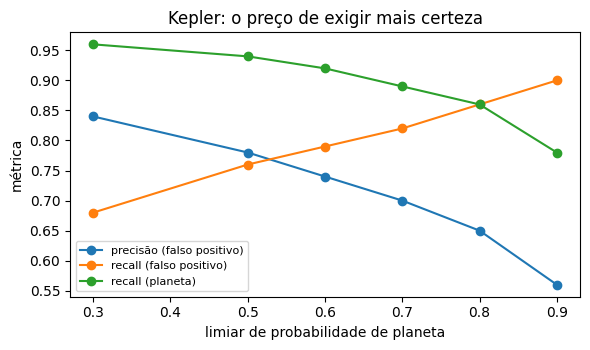

In [10]:
limiares = [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]
tab = []
for t in limiares:
    pred = (oof_hgb > t).astype(int)
    tab.append(dict(limiar=t,
                    precision_FP=precision_score(kdf.y, pred, pos_label=0),
                    recall_FP=recall_score(kdf.y, pred, pos_label=0),
                    recall_planeta=recall_score(kdf.y, pred, pos_label=1)))
tab = pd.DataFrame(tab).round(2)
print(tab.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.6))
for c, rot in [("precision_FP", "precisão (falso positivo)"), ("recall_FP", "recall (falso positivo)"),
               ("recall_planeta", "recall (planeta)")]:
    ax.plot(tab.limiar, tab[c], "o-", label=rot)
ax.set_xlabel("limiar de probabilidade de planeta"); ax.set_ylabel("métrica"); ax.legend(fontsize=8)
ax.set_title("Kepler: o preço de exigir mais certeza"); plt.tight_layout()
plt.savefig(os.path.join(OUT, "fig_limiar_kepler.png"), dpi=130); plt.show()

Escolher o limiar é uma decisão de custo: subir o limiar pega mais falsos positivos, mas descarta planetas reais. Esta tabela usa as mesmas previsões em que o limiar é lido, então é levemente otimista; serve para ver a troca, não como desempenho final.

### 2.5 Previsão para os candidatos ainda sem resposta

In [11]:
todas = fisica_kepler(koi)
final_k = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)
final_k.fit(kdf[FEATS_K2], kdf.y)

abertos = todas[todas.koi_disposition.isin(["CANDIDATE", "NOT DISPOSITIONED"])].copy()
abertos["prob_planeta"] = final_k.predict_proba(abertos[FEATS_K2])[:, 1]
print("Casos abertos:", len(abertos))
print(abertos.groupby("koi_disposition").prob_planeta.describe()[["count", "mean", "50%"]].round(2))
print("Acima de 0.7:", (abertos.prob_planeta > 0.7).sum(), "| abaixo de 0.3:", (abertos.prob_planeta < 0.3).sum())

abertos[["kepid", "kepoi_name", "koi_disposition", "koi_period", "koi_prad", "koi_model_snr", "prob_planeta"]] \
    .sort_values("prob_planeta", ascending=False) \
    .to_csv(os.path.join(OUT, "kepler_previsoes_abertos.csv"), index=False)

Casos abertos: 847
                   count  mean   50%
koi_disposition                     
CANDIDATE          268.0  0.56  0.64
NOT DISPOSITIONED  579.0  0.36  0.15
Acima de 0.7: 293 | abaixo de 0.3: 432


**Cuidados ao usar essas probabilidades:** servem para **ordenar** candidatos, não como chance literal de ser planeta (o modelo foi treinado com `class_weight="balanced"` e não está calibrado). Os candidatos abertos também são sistematicamente diferentes dos rotulados (SNR e raios maiores), então parte da previsão é extrapolação. Não existe verdade de referência para eles.

## 3. TESS: o problema dos valores faltantes

**Rótulos:** planeta = `KP` (planeta conhecido) + `CP` (confirmado); não planeta = `FP` (falso positivo) + `FA` (falso alarme). `PC` e `APC` (candidatos) ficam para a previsão.

O TESS não tem duas das features mais fortes do Kepler (`koi_impact` e o SNR do modelo). Como substituto aproximado do SNR, uso **profundidade ÷ erro da profundidade** (`log_snr_depth`). É uma aproximação minha, não a mesma grandeza.

In [12]:
def monta_tess(t):
    t = t.copy()
    t["log_period"] = np.log10(t["pl_orbper"])
    t["log_depth"]  = np.log10(t["pl_trandep"].clip(lower=1))
    t["rp_rs"]      = t["pl_rade"] / (109.1 * t["st_rad"])
    rho = (10 ** (t["st_logg"] - 4.438)) / t["st_rad"]
    t["dur_ratio"]  = t["pl_trandurh"] / (13.0 * (t["pl_orbper"] / 365.25) ** (1 / 3) * rho ** (-1 / 3))
    erro = (t["pl_trandeperr1"].abs() + t["pl_trandeperr2"].abs()) / 2
    t["log_snr_depth"] = np.log10((t["pl_trandep"] / erro).clip(lower=0.1))
    return t.replace([np.inf, -np.inf], np.nan)

FEATS_T_BASE = ["pl_orbper", "pl_trandurh", "pl_trandep", "pl_rade", "pl_eqt", "pl_insol",
                "st_tmag", "st_teff", "st_logg", "st_rad", "st_dist"]
FEATS_T_FIS  = FEATS_T_BASE + ["log_period", "log_depth", "rp_rs", "dur_ratio"]
FEATS_T      = FEATS_T_FIS + ["log_snr_depth"]
FEATS_CORE   = ["pl_orbper", "pl_trandurh", "pl_trandep", "st_tmag", "log_period", "log_depth", "log_snr_depth"]

lab = monta_tess(toi[toi.tfopwg_disp.isin(["KP", "CP", "FP", "FA"])])
lab["y"] = lab.tfopwg_disp.isin(["KP", "CP"]).astype(int)
print("Rotulados:", len(lab), "| planetas:", lab.y.sum(), "| estrelas únicas (tid):", lab.tid.nunique())

cv_t = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
def auc_t(dados, cols, imputar=False, seeds=(0,)):
    aucs = []
    for s in seeds:
        mdl = HistGradientBoostingClassifier(random_state=42)
        if imputar: mdl = make_pipeline(SimpleImputer(strategy="median"), mdl)
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        p = cross_val_predict(mdl, dados[cols], dados.y, groups=dados.tid, cv=cv, method="predict_proba")[:, 1]
        aucs.append(roc_auc_score(dados.y, p))
    return float(np.mean(aucs)), float(np.std(aucs))

print("\nROC-AUC por conjunto de features (todas as linhas):")
for nome, cols in [("só colunas originais", FEATS_T_BASE), ("+ features físicas", FEATS_T_FIS), ("+ aproximação de SNR", FEATS_T)]:
    print(f"  {nome:24s} {auc_t(lab, cols)[0]:.3f}")

Rotulados: 2242 | planetas: 1033 | estrelas únicas (tid): 2139

ROC-AUC por conjunto de features (todas as linhas):
  só colunas originais     0.919
  + features físicas       0.925
  + aproximação de SNR     0.930


### 3.1 Os nulos funcionam como atalho?

Nulo x classe no treino:
y         não planeta  planeta
tem_nulo                      
False             969     1018
True              240       15

Nulos (%) por classe:
y               0    1
pl_orbper     1.2  1.3
pl_trandurh   0.0  0.0
pl_trandep    0.0  0.0
pl_rade       9.6  0.7
pl_eqt        6.9  0.7
pl_insol      4.0  0.6
st_tmag       0.0  0.0
st_teff       3.1  0.0
st_logg      17.6  1.1
st_rad        9.6  0.7
st_dist       4.0  0.5
só indicadores de nulo         ROC-AUC = 0.575
modelo original (com nulos)    ROC-AUC = 0.930
imputação pela mediana         ROC-AUC = 0.927
só linhas completas            ROC-AUC = 0.922
(linhas completas: 1931; fração de planetas: 0.52)


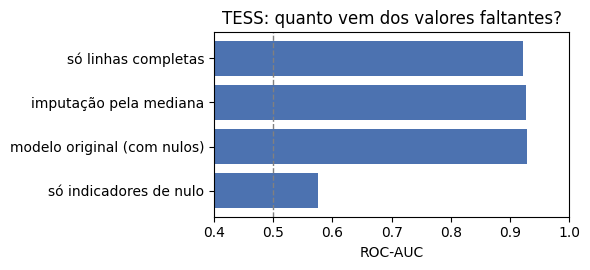

In [13]:
lab["tem_nulo"] = lab[["st_logg", "pl_rade", "st_rad"]].isna().any(axis=1)
print("Nulo x classe no treino:")
print(pd.crosstab(lab.tem_nulo, lab.y.map({0: "não planeta", 1: "planeta"})))
print("\nNulos (%) por classe:")
print(lab.groupby("y")[FEATS_T_BASE].apply(lambda g: g.isna().mean() * 100).T.round(1))

# Teste: um modelo que só vê "está faltando?", sem nenhum valor medido
ind = lab[FEATS_T].isna().astype(int).add_prefix("nulo_")
lab_ind = pd.concat([lab[["y", "tid"]], ind], axis=1)
a_ind = auc_t(lab_ind, list(ind.columns))[0]
a_full = auc_t(lab, FEATS_T)[0]
a_imp = auc_t(lab, FEATS_T, imputar=True)[0]
completas = lab.dropna(subset=FEATS_T)
a_comp = auc_t(completas, FEATS_T)[0]
resumo_nulos = {"só indicadores de nulo": a_ind, "modelo original (com nulos)": a_full,
                "imputação pela mediana": a_imp, "só linhas completas": a_comp}
for k, v_ in resumo_nulos.items():
    print(f"{k:30s} ROC-AUC = {v_:.3f}")
print(f"(linhas completas: {len(completas)}; fração de planetas: {completas.y.mean():.2f})")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(list(resumo_nulos), list(resumo_nulos.values()), color="#4c72b0")
ax.axvline(0.5, color="gray", ls="--", lw=1); ax.set_xlim(0.4, 1)
ax.set_xlabel("ROC-AUC"); ax.set_title("TESS: quanto vem dos valores faltantes?"); plt.tight_layout()
plt.savefig(os.path.join(OUT, "fig_nulos_tess.png"), dpi=130); plt.show()

Objetos com dados estelares faltando são quase todos não planetas (a falta de dados é uma propriedade de como o catálogo foi montado, não do objeto). O teste mostra que **o atalho existe, mas é pequeno**: com apenas os indicadores de nulo o AUC fica perto do acaso, e remover a pista (imputação ou só linhas completas) custa menos de 0,01. A imputação pela mediana **não esconde** o atalho, porque todas as linhas com nulo passam a ter o mesmo valor, que uma árvore consegue isolar.

### 3.2 Quais features carregam a informação (mesmas linhas completas, sem o atalho)

In [14]:
conjuntos = {
    "núcleo":                    FEATS_CORE,
    "núcleo + estrela":          FEATS_CORE + ["st_teff", "st_logg", "st_rad", "st_dist"],
    "núcleo + raio e derivadas": FEATS_CORE + ["pl_rade", "rp_rs", "dur_ratio"],
    "núcleo + eqt e insolação":  FEATS_CORE + ["pl_eqt", "pl_insol"],
    "tudo":                      FEATS_T,
}
print("ROC-AUC em 3 divisões (mesmas linhas completas para todos):")
for nome, cols in conjuntos.items():
    m_, s_ = auc_t(completas, cols, seeds=(0, 1, 2))
    print(f"  {nome:28s} média={m_:.3f}  desvio={s_:.3f}")

ROC-AUC em 3 divisões (mesmas linhas completas para todos):
  núcleo                       média=0.847  desvio=0.003
  núcleo + estrela             média=0.898  desvio=0.002
  núcleo + raio e derivadas    média=0.918  desvio=0.001
  núcleo + eqt e insolação     média=0.884  desvio=0.000
  tudo                         média=0.923  desvio=0.003


O conjunto "núcleo" (só medidas do sinal e a magnitude) fica bem abaixo do modelo com tudo. O bloco de raio e razões derivadas recupera quase todo o desempenho. Duas leituras são possíveis e os dados não separam: (a) são os critérios físicos que um astrônomo usaria; (b) o vetting que gerou os rótulos usou justamente raio e duração, e o modelo reproduz esse julgamento.

### 3.3 Previsão para os candidatos do TESS (duas camadas)

In [15]:
cand = monta_tess(toi[toi.tfopwg_disp.isin(["PC", "APC"])])
cand["completo"] = cand[FEATS_T].notna().all(axis=1)

m_full = HistGradientBoostingClassifier(random_state=42).fit(completas[FEATS_T], completas.y)
m_core = HistGradientBoostingClassifier(random_state=42).fit(lab[FEATS_CORE], lab.y)

cand["prob_final"] = np.nan
cand.loc[cand.completo, "prob_final"] = m_full.predict_proba(cand.loc[cand.completo, FEATS_T])[:, 1]
cand.loc[~cand.completo, "prob_final"] = m_core.predict_proba(cand.loc[~cand.completo, FEATS_CORE])[:, 1]
cand["confianca"] = np.where(cand.completo, "normal", "baixa")

print("Candidatos completos:", int(cand.completo.sum()), "| com algum nulo:", int((~cand.completo).sum()))
print(cand.groupby(["confianca", "tfopwg_disp"]).prob_final.agg(["count", "mean", "median"]).round(2))
cand[["toi", "tid", "tfopwg_disp", "pl_orbper", "pl_rade", "prob_final", "confianca"]] \
    .sort_values("prob_final", ascending=False) \
    .to_csv(os.path.join(OUT, "tess_previsoes_candidatos.csv"), index=False)

Candidatos completos: 4375 | com algum nulo: 753
                       count  mean  median
confianca tfopwg_disp                     
baixa     APC            101  0.36    0.28
          PC             652  0.38    0.31
normal    APC            337  0.26    0.08
          PC            4038  0.55    0.63


Modelo completo (treinado só em linhas completas) para os candidatos sem nenhum valor faltando; modelo "núcleo" para os demais, marcados com `confianca = "baixa"`. As duas camadas **não estão na mesma escala**: ao priorizar alvos, ordene cada camada separadamente. Os candidatos do TESS também estão em estrelas mais fracas que as do treino, então parte da previsão é extrapolação.

## 4. O que aprendi vale entre missões?

Treino numa missão e teste na outra, só com as features que existem nas duas tabelas (12 medidas), só linhas completas, e o ROC-AUC como métrica (não depende do equilíbrio entre classes, que é 77% de planetas no Kepler e ~51% no TESS).

Kepler: 3018 | planetas: 0.77    TESS: 1940 | planetas: 0.51

Medianas das features comuns (note as escalas diferentes):
             Kepler     TESS
period         8.87     3.66
duration       3.38     2.68
depth        460.00  3699.00
rade           2.14     9.81
teq          820.00  1288.58
teff        5711.00  5832.92
logg           4.50     4.33
srad           0.92     1.24
log_period     0.95     0.56
log_depth      2.66     3.57
rp_rs          0.02     0.06
dur_ratio      0.96     0.85

ROC-AUC:
  Kepler → Kepler    0.866
  TESS → TESS        0.899
  Kepler → TESS      0.819
  TESS → Kepler      0.807


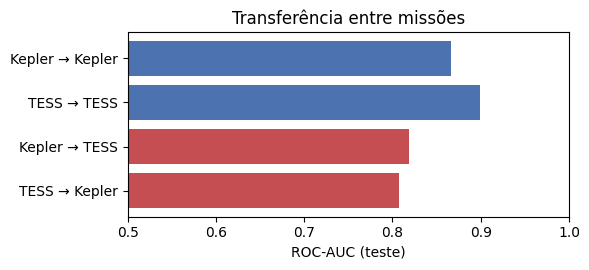

In [16]:
mapa = {  # nome comum: (coluna no Kepler, coluna no TESS)
    "period": ("koi_period", "pl_orbper"), "duration": ("koi_duration", "pl_trandurh"),
    "depth": ("koi_depth", "pl_trandep"), "rade": ("koi_prad", "pl_rade"),
    "teq": ("koi_teq", "pl_eqt"), "teff": ("koi_steff", "st_teff"),
    "logg": ("koi_slogg", "st_logg"), "srad": ("koi_srad", "st_rad"),
    "log_period": ("log_period", "log_period"), "log_depth": ("log_depth", "log_depth"),
    "rp_rs": ("rp_rs", "rp_rs"), "dur_ratio": ("dur_ratio", "dur_ratio"),
}
comuns = list(mapa)
K = kdf[["kepid", "y"] + [v[0] for v in mapa.values()]].copy(); K.columns = ["grupo", "y"] + comuns
T = lab[["tid", "y"] + [v[1] for v in mapa.values()]].copy();   T.columns = ["grupo", "y"] + comuns
K, T = K.dropna(), T.dropna()
print("Kepler:", len(K), "| planetas:", round(K.y.mean(), 2), "   TESS:", len(T), "| planetas:", round(T.y.mean(), 2))
print("\nMedianas das features comuns (note as escalas diferentes):")
print(pd.DataFrame({"Kepler": K[comuns].median(), "TESS": T[comuns].median()}).round(2))

hgb = lambda: HistGradientBoostingClassifier(random_state=42)
def cv_auc(D):
    p = cross_val_predict(hgb(), D[comuns], D.y, groups=D.grupo, cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
    return roc_auc_score(D.y, p)

transf = {
    "Kepler → Kepler": cv_auc(K),
    "TESS → TESS":     cv_auc(T),
    "Kepler → TESS":   roc_auc_score(T.y, hgb().fit(K[comuns], K.y).predict_proba(T[comuns])[:, 1]),
    "TESS → Kepler":   roc_auc_score(K.y, hgb().fit(T[comuns], T.y).predict_proba(K[comuns])[:, 1]),
}
print("\nROC-AUC:")
for k, v_ in transf.items(): print(f"  {k:18s} {v_:.3f}")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(list(transf)[::-1], list(transf.values())[::-1], color=["#c44e52", "#c44e52", "#4c72b0", "#4c72b0"])
ax.set_xlim(0.5, 1); ax.set_xlabel("ROC-AUC (teste)"); ax.set_title("Transferência entre missões")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_transferencia.png"), dpi=130); plt.show()

Há sinal compartilhado (as duas transferências ficam bem acima de 0,5), mas **perde-se 0,06 a 0,09 de AUC** em relação a treinar na própria missão. Testei três explicações para essa perda e nenhuma se confirmou: restringir a uma região de medidas em que as duas missões têm exemplos (raio de 2 a 15 R⊕, período de 1 a 30 dias) não reduziu a perda; usar só razões físicas transferiu **pior**; e tirar as variáveis de escala absoluta não ajudou. Uma hipótese que não testei: os rótulos de KOI e TOI vêm de processos de vetting diferentes.

## 5. Segunda fase: curvas de luz do Kepler

As tabelas parecem ter um teto. A pergunta agora é se medir o trânsito **diretamente na curva de luz** acrescenta informação. Para cada KOI, dobro a curva de luz na efeméride do catálogo (`koi_period`, `koi_time0bk`) e meço:

| Feature | O que mede |
|---|---|
| `snr_emp` | profundidade ÷ ruído medido em fases aleatórias (já desconta o ruído correlacionado) |
| `abs_odd_even` | diferença de profundidade entre trânsitos pares e ímpares, em sigmas |
| `sec_sigma` | profundidade na fase 0,5 (eclipse secundário), em sigmas |
| `core_ratio` | profundidade no centro ÷ profundidade média na janela (trânsito em "V" × em "U") |
| `depth_vs_cat` | profundidade medida ÷ profundidade do catálogo |

Decisões que afetam os resultados: só corto pontos **acima** da média (raios cósmicos), nunca abaixo, porque um eclipse profundo de binária é exatamente o que quero medir; uso `SAP_QUALITY == 0`; mascaro os trânsitos dos **outros KOIs da mesma estrela** antes de medir o alvo.

### 5.1 Extração (desligada por padrão)
Os arquivos vêm do endpoint de download do MAST. Os carimbos de data/hora no nome de cada arquivo são comuns a todas as estrelas de um trimestre. Nesta execução, o servidor de **busca** do MAST (usado pelo `lightkurve`) travou, então baixei os arquivos diretamente. Cada estrela é baixada, processada e **apagada**, para o disco não crescer.

In [17]:
if RUN_EXTRACTION:
    import lightkurve as lk
    from astropy.io import fits
    import requests
    from concurrent.futures import ThreadPoolExecutor

    SAIDA = os.path.join(OUT, "features_lc_1000.csv")
    try:
        TMP = "/kaggle/tmp/Kepler"; os.makedirs(TMP, exist_ok=True)
    except Exception:
        TMP = "/tmp/Kepler"; os.makedirs(TMP, exist_ok=True)

    CARIMBOS = {0: "2009131105131", 1: "2009166043257", 2: "2009259160929", 3: "2009350155506",
                4: "2010078095331", 5: "2010174085026", 6: "2010265121752", 7: "2010355172524",
                8: "2011073133259", 9: "2011177032512", 10: "2011271113734", 11: "2012004120508",
                12: "2012088054726", 13: "2012179063303", 14: "2012277125453", 15: "2013011073258",
                16: "2013098041711", 17: "2013131215648"}

    rot = koi[koi.koi_disposition.isin(["CONFIRMED", "FALSE POSITIVE"])]
    amostra = pd.concat([rot[rot.koi_disposition == "CONFIRMED"].sample(N_POR_CLASSE, random_state=1),
                         rot[rot.koi_disposition == "FALSE POSITIVE"].sample(N_POR_CLASSE, random_state=1)])
    amostra = amostra[["kepoi_name", "kepid", "koi_disposition", "koi_period", "koi_time0bk", "koi_duration", "koi_depth"]]
    print(f"Amostra: {len(amostra)} KOIs em {amostra.kepid.nunique()} estrelas")

    def pasta_estrela(kid):
        s = f"{kid:09d}"; return os.path.join(TMP, s[:4], s)

    def baixa(kid, q):
        s, c = f"{kid:09d}", CARIMBOS[q]
        dest = f"{pasta_estrela(kid)}/kplr{s}-{c}_llc.fits"
        if os.path.exists(dest) and os.path.getsize(dest) > 10000: return "OK"
        url = ("https://mast.stsci.edu/api/v0.1/Download/file?uri="
               f"mast:Kepler/url/missions/kepler/lightcurves/{s[:4]}/{s}//kplr{s}-{c}_llc.fits")
        st = "erro"
        for tent in range(3):
            try:
                r = requests.get(url, timeout=(30, 120))
                if r.status_code == 404: return "404"          # estrela sem dados nesse trimestre
                if r.status_code == 200 and r.content.startswith(b"SIMPLE"):
                    os.makedirs(os.path.dirname(dest), exist_ok=True)
                    open(dest + ".part", "wb").write(r.content); os.replace(dest + ".part", dest)
                    return "OK"
                st = f"HTTP {r.status_code}"
            except Exception as e:
                st = f"erro {type(e).__name__}"
            time.sleep(2 * (tent + 1))
        return st

    def carrega(kid):
        ts, fs = [], []
        for a in sorted(glob.glob(f"{pasta_estrela(kid)}/*_llc.fits")):
            with fits.open(a) as h:
                d = h[1].data; t, f, q = d["TIME"], d["PDCSAP_FLUX"], d["SAP_QUALITY"]
            ok = np.isfinite(t) & np.isfinite(f) & (q == 0)
            if ok.sum() < 100: continue
            t, f = t[ok].astype(float), f[ok].astype(float)
            ts.append(t); fs.append(f / np.median(f))
        if not ts: return None, None
        t, f = np.concatenate(ts), np.concatenate(fs); o = np.argsort(t)
        return t[o], f[o]

    def mascara(t, P, T0, larg):
        return np.abs(((t - T0 + 0.5 * P) % P) - 0.5 * P) < larg / 2

    def prepara_fase(t, f, T0, P):
        ph = (t - T0) % P; o = np.argsort(ph); ph, ff = ph[o], f[o]
        return np.concatenate([ph - P, ph, ph + P]), np.concatenate([[0.0], np.cumsum(np.concatenate([ff, ff, ff]))])

    def media_janela(ph3, cs, centros, larg):
        lo = np.searchsorted(ph3, centros - larg / 2); hi = np.searchsorted(ph3, centros + larg / 2)
        n = hi - lo
        return np.where(n > 0, (cs[hi] - cs[lo]) / np.maximum(n, 1), np.nan), n

    def processa_estrela(kid, alvos):
        t, f = carrega(kid)
        if t is None:
            return [dict(kepoi_name=r.kepoi_name, kepid=kid, status="sem_arquivos") for r in alvos.itertuples()]
        todos = koi[koi.kepid == kid].dropna(subset=["koi_period", "koi_time0bk", "koi_duration"])
        efem = [(r.kepoi_name, r.koi_period, r.koi_time0bk, r.koi_duration / 24) for r in todos.itertuples()]
        m_all = np.zeros(len(t), bool)
        for _, P, T0, D in efem: m_all |= mascara(t, P, T0, 1.5 * D)
        wl = int(max(101, round(3 * max(e[3] for e in efem) * 48.98)))
        wl = min(wl + (wl % 2 == 0), 2001)
        flat = lk.LightCurve(time=t, flux=f).flatten(window_length=wl, mask=m_all)
        ff, tt = np.asarray(flat.flux.value, float), np.asarray(flat.time.value, float)
        med = np.median(ff); sd = 1.4826 * np.median(np.abs(ff - med))
        k = ff < med + 5 * sd                                   # só corta para cima
        tt, ff = tt[k], ff[k]
        saida = []
        for r in alvos.itertuples():
            d = dict(kepoi_name=r.kepoi_name, kepid=kid, n_pontos=len(tt))
            P, T0, D = r.koi_period, r.koi_time0bk, r.koi_duration / 24
            if not (np.isfinite([P, T0, D]).all() and 0 < D < 0.4 * P):
                d["status"] = "efemeride_invalida"; saida.append(d); continue
            outros = np.zeros(len(tt), bool)
            for nome, P2, T2, D2 in efem:
                if nome != r.kepoi_name: outros |= mascara(tt, P2, T2, 1.5 * D2)
            t2, f2 = tt[~outros], ff[~outros]
            fc = ((t2 - T0 + 0.5 * P) % P) - 0.5 * P
            dentro = np.abs(fc) < D / 2; n_in = int(dentro.sum())
            if n_in < 10:
                d["status"] = "poucos_pontos_em_transito"; saida.append(d); continue
            base = f2[np.abs(fc) >= D].mean()
            ph3, cs = prepara_fase(t2, f2, T0, P)
            m0, _ = media_janela(ph3, cs, np.array([0.0]), D); depth = base - m0[0]
            c = np.arange(0, P, D / 4)
            c = c[(np.minimum(c, P - c) > D) & (np.abs(c - P / 2) > D)]
            mj, nj = media_janela(ph3, cs, c, D); bom = nj >= 0.5 * n_in
            sig = (base - mj[bom]).std() if bom.sum() >= 10 else np.nan     # ruído empírico
            mc, _ = media_janela(ph3, cs, np.array([0.0]), D / 3)
            ms, _ = media_janela(ph3, cs, np.array([P / 2]), D)
            ciclo = np.round((t2 - T0) / P).astype(int); par = ciclo % 2 == 0
            n_par, n_imp = int((dentro & par).sum()), int((dentro & ~par).sum())
            oe = np.nan
            if n_par >= 3 and n_imp >= 3 and np.isfinite(sig):
                dp, di = base - f2[dentro & par].mean(), base - f2[dentro & ~par].mean()
                oe = (dp - di) / (sig * np.sqrt(n_in) * np.sqrt(1 / n_par + 1 / n_imp))
            d.update(status="OK", n_transitos=len(np.unique(ciclo[dentro])), n_in=n_in,
                     depth_ppm=depth * 1e6, sig_ppm=sig * 1e6,
                     snr_emp=depth / sig if np.isfinite(sig) else np.nan,
                     odd_even_sigma=oe, sec_depth_ppm=(base - ms[0]) * 1e6,
                     sec_sigma=(base - ms[0]) / sig if np.isfinite(sig) else np.nan,
                     core_ratio=(base - mc[0]) / depth if depth > 0 else np.nan,
                     depth_vs_cat=depth * 1e6 / r.koi_depth if r.koi_depth > 0 else np.nan)
            saida.append(d)
        return saida

    feitos = set(pd.read_csv(SAIDA).kepid) if os.path.exists(SAIDA) else set()
    t_ini, n_est, falhas = time.time(), 0, []
    estrelas = [(k, g) for k, g in amostra.groupby("kepid") if k not in feitos]
    print(f"Estrelas pendentes: {len(estrelas)}")
    for kid, g in estrelas:
        if time.time() - t_ini > LIMITE_MIN * 60:
            print(f"Limite de {LIMITE_MIN} min atingido, parando."); break
        kid = int(kid)
        with ThreadPoolExecutor(N_THREADS) as ex:
            sts = list(ex.map(lambda q: baixa(kid, q), CARIMBOS))
        if any(s not in ("OK", "404") for s in sts):           # não processa com dados parciais
            falhas.append((kid, sorted(set(sts)))); shutil.rmtree(pasta_estrela(kid), ignore_errors=True); continue
        try:
            linhas = processa_estrela(kid, g)
        except Exception as e:
            linhas = [dict(kepoi_name=r.kepoi_name, kepid=kid, status=f"erro: {type(e).__name__}: {str(e)[:80]}") for r in g.itertuples()]
        shutil.rmtree(pasta_estrela(kid), ignore_errors=True)
        pd.DataFrame(linhas).to_csv(SAIDA, mode="a", header=not os.path.exists(SAIDA), index=False)
        n_est += 1
        if n_est % 25 == 0:
            dt = time.time() - t_ini
            print(f"  {n_est} estrelas em {dt/60:.1f} min ({n_est/dt*3600:.0f}/h) | falhas de download: {len(falhas)}")

    res_ext = pd.read_csv(SAIDA)
    print(f"\nKOIs processados: {len(res_ext)} de {len(amostra)} | estrelas com falha de download: {len(falhas)}")
    print("Status:", res_ext.status.value_counts().to_dict())

### 5.2 Verificação: Kepler-10 b (desligada por padrão)
Teste do pipeline com um planeta conhecido. Com só o trimestre Q0 (10 dias, 469 pontos), o BLS já recupera o sinal; com os 14 trimestres disponíveis (1.245 trânsitos), a profundidade medida (≈160 ppm) fica perto da do catálogo (195 ppm), a diferença entre trânsitos pares e ímpares some (−0,7 sigma) e o "eclipse secundário" de 30 ppm que parecia existir no Q0 cai para 2,7 ppm (1,1 sigma). Ou seja, aquele secundário era ruído, e **o ruído real foi cerca de 2 vezes o de ruído branco**, motivo pelo qual o ruído é medido em fases aleatórias.

In [18]:
if RUN_EXTRACTION:
    print("Download Kepler-10 (Q0):", baixa(11904151, 0))
    arq = glob.glob(f"{pasta_estrela(11904151)}/*_llc.fits")[0]
    lc10 = lk.read(arq).remove_nans().remove_outliers(sigma=5)
    flat10 = lc10.flatten(window_length=49)
    bls10 = flat10.to_periodogram(method="bls", period=np.linspace(0.5, 5.0, 20000), duration=[0.04, 0.06, 0.08])
    P10 = float(bls10.period_at_max_power.value); t10 = float(bls10.transit_time_at_max_power.value)
    cat = koi[koi.kepoi_name == "K00072.01"].iloc[0]
    print(f"BLS (Q0): P = {P10:.4f} d, profundidade = {float(np.asarray(bls10.depth_at_max_power))*1e6:.0f} ppm")
    print(f"Catálogo KOI: P = {cat.koi_period:.6f} d, profundidade = {cat.koi_depth:.0f} ppm")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    bls10.plot(ax=ax[0]); ax[0].set_title("Periodograma BLS (Q0)")
    dob = flat10.fold(period=P10, epoch_time=t10)
    dob.scatter(ax=ax[1], s=3, alpha=0.4); dob.bin(time_bin_size=0.01).plot(ax=ax[1], color="red", lw=2)
    ax[1].set_xlim(-0.4 * P10, 0.4 * P10); ax[1].set_title(f"Dobrada em P = {P10:.4f} d")
    plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_kepler10.png"), dpi=130); plt.show()

### 5.3 As features da curva de luz acrescentam informação?

In [23]:
try:
    f_lc = find("features_lc_1000.csv"); LC_OK = True
    print("Features das curvas de luz:", f_lc)
except FileNotFoundError:
    LC_OK = False
    print("features_lc_1000.csv não encontrado: as células 5.3 a 5.5 serão puladas.")
    print("Use RUN_EXTRACTION = True ou adicione o CSV como entrada do notebook.")

Features das curvas de luz: /kaggle/input/datasets/carlospetito/features-lc-1000-csv/features_lc_1000.csv


In [24]:
if LC_OK:
    lcf = pd.read_csv(f_lc)
    cols_koi = ["kepoi_name", "koi_disposition", "koi_period", "koi_duration", "koi_depth",
                "koi_impact", "koi_model_snr", "koi_prad", "koi_teq", "koi_steff",
                "koi_slogg", "koi_srad", "koi_kepmag"]
    dlc = lcf[lcf.status == "OK"].merge(koi[cols_koi], on="kepoi_name", how="left")
    dlc["y"] = (dlc.koi_disposition == "CONFIRMED").astype(int)
    dlc = fisica_kepler(dlc)
    dlc["abs_odd_even"] = dlc.odd_even_sigma.abs()
    dlc = dlc.replace([np.inf, -np.inf], np.nan).reset_index(drop=True)

    FEATS_TAB = FEATS_K2
    FEATS_LC = ["snr_emp", "abs_odd_even", "sec_sigma", "core_ratio", "depth_vs_cat"]
    print(f"Linhas: {len(dlc)} | planetas: {dlc.y.sum()} | falsos positivos: {(1 - dlc.y).sum()} | estrelas: {dlc.kepid.nunique()}")
    print("NaN nas features da curva (%):", (dlc[FEATS_LC].isna().mean() * 100).round(1).to_dict())
    print("\nAUC univariado (planeta = positivo):")
    print(f"{'feature':14s} {'n':>5s} {'med(FP)':>10s} {'med(planeta)':>13s} {'AUC':>6s}")
    for c in FEATS_LC + ["koi_model_snr", "koi_impact", "koi_period", "koi_duration", "koi_depth", "rp_rs", "dur_ratio"]:
        x = dlc.dropna(subset=[c])
        print(f"{c:14s} {len(x):5d} {x[x.y == 0][c].median():10.2f} {x[x.y == 1][c].median():13.2f} {roc_auc_score(x.y, x[c]):6.3f}")

    refs = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr"]
    A = pd.DataFrame({r: [spearmanr(dlc[c], dlc[r], nan_policy="omit")[0] for c in FEATS_LC] for r in refs}, index=FEATS_LC).round(2)
    print("\nSpearman: features da curva (linhas) x medidas da tabela (colunas)"); print(A)

    def por_faixa(var):
        q = pd.qcut(dlc[var], 3, labels=["baixo", "medio", "alto"])
        comp = {f: f"{int(dlc[q == f].y.sum())}/{int((q == f).sum())}" for f in ["baixo", "medio", "alto"]}
        print(f"\nAUC dentro de tercis de {var} (planetas/total: {comp})")
        for c in FEATS_LC:
            partes = []
            for f in ["baixo", "medio", "alto"]:
                g = dlc[q == f].dropna(subset=[c])
                ok = g.y.sum() >= 15 and (1 - g.y).sum() >= 15
                partes.append(f"{roc_auc_score(g.y, g[c]):.2f}" if ok else " n/a")
            print(f"   {c:14s} baixo={partes[0]}  medio={partes[1]}  alto={partes[2]}")
    por_faixa("koi_period"); por_faixa("koi_duration")

Linhas: 999 | planetas: 500 | falsos positivos: 499 | estrelas: 964
NaN nas features da curva (%): {'snr_emp': 3.0, 'abs_odd_even': 3.1, 'sec_sigma': 3.0, 'core_ratio': 0.5, 'depth_vs_cat': 0.0}

AUC univariado (planeta = positivo):
feature            n    med(FP)  med(planeta)    AUC
snr_emp          969      24.57         24.23  0.527
abs_odd_even     968       1.02          0.89  0.455
sec_sigma        969       0.48          0.07  0.375
core_ratio       994       1.30          1.21  0.274
depth_vs_cat     999       0.71          0.80  0.685
koi_model_snr    999      45.80         37.85  0.464
koi_impact       999       0.48          0.68  0.541
koi_period       999       3.56         10.02  0.695
koi_duration     999       3.09          3.42  0.544
koi_depth        999     388.00        492.00  0.534
rp_rs            999       0.02          0.02  0.521
dur_ratio        999       1.08          0.94  0.388

Spearman: features da curva (linhas) x medidas da tabela (colunas)
          

Na minha execução, os AUC univariados indicam que `core_ratio` (trânsitos mais "pontudos" em falsos positivos), `sec_sigma` (eclipse secundário) e `depth_vs_cat` separam as classes, e o padrão se mantém dentro de faixas de período e de duração. Isso afasta a hipótese de que fossem apenas um substituto da duração do trânsito.

### 5.4 Tabela × tabela + curva de luz

ROC-AUC (10 divisões diferentes, separadas por estrela)
   só tabela        média=0.911  desvio entre divisões=0.004
   tabela + curva   média=0.943  desvio entre divisões=0.002
   só curva         média=0.902  desvio entre divisões=0.004
   Diferença pareada: +0.031 | positiva em 100% das divisões

Bootstrap por estrela: AUC tabela=0.916 | tabela+curva=0.947
   Diferença: +0.030 | IC 95% = [+0.019, +0.042]

Ablação (AUC das previsões médias)
   só tabela                            0.916
   tabela + snr_emp                     0.923  (+0.006)
   tabela + abs_odd_even                0.916  (-0.000)
   tabela + sec_sigma                   0.927  (+0.011)
   tabela + core_ratio                  0.929  (+0.012)
   tabela + depth_vs_cat                0.923  (+0.007)
   tabela + todas as 5                  0.947  (+0.030)
   tabela + todas SEM snr_emp           0.945  (-0.001 vs. todas)
   tabela + todas SEM abs_odd_even      0.944  (-0.002 vs. todas)
   tabela + todas SEM sec_sigma        

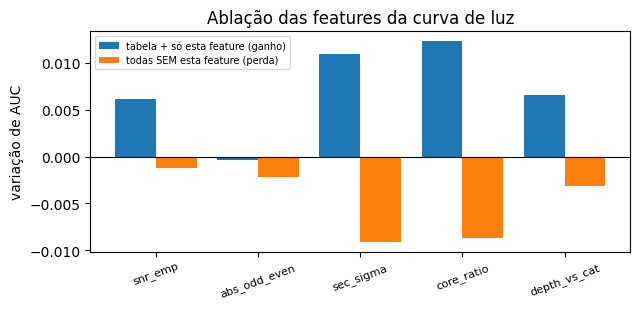

In [25]:
if LC_OK:
    def oof_lc(cols, n_rep=10):
        P, aucs = np.zeros(len(dlc)), []
        for s in range(n_rep):
            cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
            m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                               min_samples_leaf=8, random_state=0)
            p = cross_val_predict(m, dlc[cols], dlc.y, groups=dlc.kepid, cv=cv, method="predict_proba")[:, 1]
            P += p; aucs.append(roc_auc_score(dlc.y, p))
        return P / n_rep, np.array(aucs)

    p_tab, a_tab = oof_lc(FEATS_TAB)
    p_both, a_both = oof_lc(FEATS_TAB + FEATS_LC)
    _, a_lc = oof_lc(FEATS_LC)
    print("ROC-AUC (10 divisões diferentes, separadas por estrela)")
    for nome, a in [("só tabela", a_tab), ("tabela + curva", a_both), ("só curva", a_lc)]:
        print(f"   {nome:16s} média={a.mean():.3f}  desvio entre divisões={a.std():.3f}")
    d_ = a_both - a_tab
    print(f"   Diferença pareada: {d_.mean():+.3f} | positiva em {(d_ > 0).mean() * 100:.0f}% das divisões")

    # Bootstrap por estrela da diferença (sobre as previsões médias das 10 divisões)
    estrelas = dlc.kepid.unique()
    idx_por = {k: np.where(dlc.kepid.values == k)[0] for k in estrelas}
    rng = np.random.default_rng(0); difs = []
    for _ in range(1000):
        sel = rng.choice(estrelas, len(estrelas), replace=True)
        idx = np.concatenate([idx_por[k] for k in sel]); yy = dlc.y.values[idx]
        if yy.min() != yy.max():
            difs.append(roc_auc_score(yy, p_both[idx]) - roc_auc_score(yy, p_tab[idx]))
    difs = np.array(difs)
    print(f"\nBootstrap por estrela: AUC tabela={roc_auc_score(dlc.y, p_tab):.3f} | tabela+curva={roc_auc_score(dlc.y, p_both):.3f}")
    print(f"   Diferença: {difs.mean():+.3f} | IC 95% = [{np.percentile(difs, 2.5):+.3f}, {np.percentile(difs, 97.5):+.3f}]")

    # Ablação
    base_auc, tudo = roc_auc_score(dlc.y, p_tab), roc_auc_score(dlc.y, p_both)
    abl = {}
    print("\nAblação (AUC das previsões médias)")
    print(f"   {'só tabela':36s} {base_auc:.3f}")
    for c in FEATS_LC:
        a = roc_auc_score(dlc.y, oof_lc(FEATS_TAB + [c])[0]); abl[c] = (a - base_auc, None)
        print(f"   {'tabela + ' + c:36s} {a:.3f}  ({a - base_auc:+.3f})")
    print(f"   {'tabela + todas as 5':36s} {tudo:.3f}  ({tudo - base_auc:+.3f})")
    for c in FEATS_LC:
        a = roc_auc_score(dlc.y, oof_lc(FEATS_TAB + [x for x in FEATS_LC if x != c])[0])
        abl[c] = (abl[c][0], a - tudo)
        print(f"   {'tabela + todas SEM ' + c:36s} {a:.3f}  ({a - tudo:+.3f} vs. todas)")

    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    nomes = list(abl); xs = np.arange(len(nomes))
    ax.bar(xs - 0.2, [abl[n][0] for n in nomes], 0.4, label="tabela + só esta feature (ganho)")
    ax.bar(xs + 0.2, [abl[n][1] for n in nomes], 0.4, label="todas SEM esta feature (perda)")
    ax.set_xticks(xs); ax.set_xticklabels(nomes, rotation=20, fontsize=8); ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("variação de AUC"); ax.legend(fontsize=7); ax.set_title("Ablação das features da curva de luz")
    plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_ablacao_lc.png"), dpi=130); plt.show()

**Como ler a ablação:** diferenças menores que ~0,01 são ruído nesta amostra (~1.000 linhas). O robusto é o ganho **combinado**; atribuí-lo a features individuais é frágil. Com 200 linhas, parecia que só `core_ratio` e `sec_sigma` carregavam o ganho; com 1.000 o quadro ficou mais distribuído, embora essas duas continuem as mais importantes.

### 5.5 Onde o ganho aparece e o que ele vale na prática

Ganho de AUC por tercil de período (previsões médias de 10 divisões)
   baixo  n=333 planetas= 80 | tabela=0.924 tabela+curva=0.971 | diferença=+0.047  IC95%=[+0.027, +0.069]
   medio  n=333 planetas=207 | tabela=0.879 tabela+curva=0.924 | diferença=+0.045  IC95%=[+0.018, +0.076]
   alto   n=333 planetas=213 | tabela=0.889 tabela+curva=0.903 | diferença=+0.014  IC95%=[-0.011, +0.038]

Falsos positivos que PASSAM (de 499) mantendo uma fração dos planetas
   mantendo 90% dos planetas -> só tabela: 107 | tabela + curva: 67
   mantendo 95% dos planetas -> só tabela: 159 | tabela + curva: 92
   mantendo 98% dos planetas -> só tabela: 219 | tabela + curva: 157


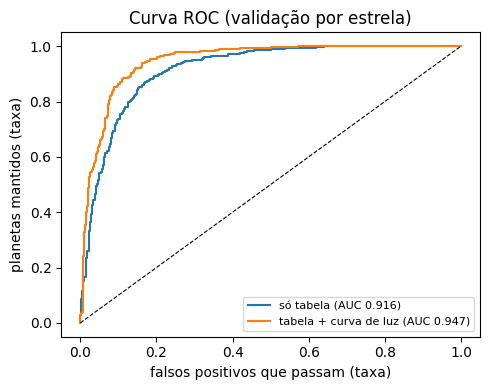


Falsos positivos que a curva REBAIXOU mais (acertos novos):
kepoi_name  koi_period  p_tab  p_both  core_ratio  sec_sigma
 K02301.01        3.51   0.85    0.13        1.21       5.55
 K00822.01        7.92   0.79    0.11        1.37       7.75
 K02892.01       10.64   0.81    0.19        1.15       3.59
 K01378.02        1.38   0.63    0.03        1.49       8.83
 K02118.01        3.21   0.68    0.08        1.25       2.96
 K02645.01        1.71   0.71    0.14        1.54       2.47

Falsos positivos que a curva ELEVOU mais (erros novos):
kepoi_name  koi_period  p_tab  p_both  core_ratio  sec_sigma
 K01343.01        1.54   0.07    0.51        1.19       0.62
 K01119.01        7.24   0.42    0.86        1.19       0.36
 K02609.01        5.60   0.35    0.79        1.22       1.35
 K02765.01        2.76   0.18    0.61        1.22      -0.70
 K03006.01        1.00   0.08    0.49        1.13       1.08
 K02952.01        1.76   0.24    0.64        1.14      -1.45

Planetas que a curva REBAIX

In [26]:
if LC_OK:
    q = pd.qcut(dlc.koi_period, 3, labels=["baixo", "medio", "alto"])
    def boot_diff(mask, n=500, seed=0):
        sub = np.where(mask)[0]; est = dlc.kepid.values[sub]; ue = np.unique(est)
        por = {k: sub[est == k] for k in ue}; rng = np.random.default_rng(seed); out = []
        for _ in range(n):
            sel = rng.choice(ue, len(ue), replace=True)
            idx = np.concatenate([por[k] for k in sel]); yy = dlc.y.values[idx]
            if yy.min() != yy.max():
                out.append(roc_auc_score(yy, p_both[idx]) - roc_auc_score(yy, p_tab[idx]))
        return np.array(out)

    print("Ganho de AUC por tercil de período (previsões médias de 10 divisões)")
    for f in ["baixo", "medio", "alto"]:
        m = (q == f).values; dd = boot_diff(m)
        print(f"   {f:6s} n={m.sum():3d} planetas={int(dlc.y[m].sum()):3d} | "
              f"tabela={roc_auc_score(dlc.y[m], p_tab[m]):.3f} tabela+curva={roc_auc_score(dlc.y[m], p_both[m]):.3f} | "
              f"diferença={dd.mean():+.3f}  IC95%=[{np.percentile(dd, 2.5):+.3f}, {np.percentile(dd, 97.5):+.3f}]")

    n_fp = int((1 - dlc.y).sum())
    print(f"\nFalsos positivos que PASSAM (de {n_fp}) mantendo uma fração dos planetas")
    for alvo in [0.90, 0.95, 0.98]:
        linhas = []
        for nome, p in [("só tabela", p_tab), ("tabela + curva", p_both)]:
            fpr, tpr, _ = roc_curve(dlc.y, p)
            linhas.append(f"{nome}: {np.interp(alvo, tpr, fpr) * n_fp:.0f}")
        print(f"   mantendo {alvo:.0%} dos planetas -> " + " | ".join(linhas))

    fig, ax = plt.subplots(figsize=(5, 4))
    for nome, p in [("só tabela", p_tab), ("tabela + curva de luz", p_both)]:
        fpr, tpr, _ = roc_curve(dlc.y, p); ax.plot(fpr, tpr, label=f"{nome} (AUC {roc_auc_score(dlc.y, p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlabel("falsos positivos que passam (taxa)")
    ax.set_ylabel("planetas mantidos (taxa)"); ax.legend(fontsize=8); ax.set_title("Curva ROC (validação por estrela)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_roc_lc.png"), dpi=130); plt.show()

    dlc["delta"] = p_both - p_tab; dlc["p_tab"] = p_tab; dlc["p_both"] = p_both
    cols = ["kepoi_name", "koi_period", "p_tab", "p_both", "core_ratio", "sec_sigma"]
    print("\nFalsos positivos que a curva REBAIXOU mais (acertos novos):")
    print(dlc[dlc.y == 0].nsmallest(6, "delta")[cols].round(2).to_string(index=False))
    print("\nFalsos positivos que a curva ELEVOU mais (erros novos):")
    print(dlc[dlc.y == 0].nlargest(6, "delta")[cols].round(2).to_string(index=False))
    print("\nPlanetas que a curva REBAIXOU mais (erros novos):")
    print(dlc[dlc.y == 1].nsmallest(6, "delta")[cols].round(2).to_string(index=False))

**Leitura dos casos:** os falsos positivos rebaixados têm eclipse secundário significativo e trânsito "pontudo", o que é o esperado de binárias eclipsantes. Os erros novos mostram os limites do método: falsos positivos que parecem planetas na curva (o rótulo deve vir de algo que a curva de fluxo não mostra, como um deslocamento do centroide, que não pude verificar) e planetas reais com trânsito rasante ou de período longo, penalizados por terem forma em "V" ou poucos trânsitos.

## 6. Limitações

- **Circularidade dos rótulos.** `CONFIRMED` e `FALSE POSITIVE` vêm de um vetting que usa critérios parecidos com as features (SNR, duração, eclipse secundário, forma). O modelo não vê os rótulos nem as flags, então não há vazamento direto, mas o AUC mede o quanto o modelo **reproduz esse julgamento**, não a natureza física dos objetos. Para candidatos novos, ainda sem vetting, isso seria útil como triagem automática, mas não é uma descoberta.
- **Sem verdade de referência** para os candidatos abertos (Kepler e TESS). As probabilidades servem para ordenar, não são calibradas.
- **Amostra das curvas de luz balanceada (50/50)**, diferente da tabela (77/23): vale para comparar modelos por AUC, não para precisão e recall absolutos. As contagens de falsos positivos na seção 5.5 vêm de uma única amostra, sem intervalo de confiança.
- **Os 1.000 KOIs incluem parte dos 200 usados no primeiro lote**, então os resultados não são totalmente independentes dos exploratórios.
- **Hiperparâmetros fixos**, escolhidos a priori e sem ajuste nestes dados, para não criar mais um grau de liberdade.
- **Aproximações no TESS:** `log_snr_depth` não é o SNR do pipeline; o atalho dos valores faltantes é pequeno, mas existe.
- **O método não vê** falsos positivos por contaminação ou deslocamento de centroide.
- Os candidatos (Kepler e TESS) estão em regiões de medidas ligeiramente diferentes do treino, então parte das previsões é extrapolação.

## 7. Próximos passos
- Aplicar o modelo com features de curva de luz aos candidatos abertos do Kepler (≈850 KOIs, cerca de 1h20 de extração) e comparar o ranking com o do modelo só de tabela.
- Repetir a extração de features no TESS (curvas do SPOC).
- Calibrar as probabilidades e reportar precisão e recall com a prevalência real de planetas.
- Testar uma CNN 1D na curva dobrada, usando as features atuais como linha de base.